# Logistic Regression Baseline

This notebook trains a multinomial Logistic Regression classifier to predict the
financial **Product** (11 classes) from the cleaned CFPB complaint narrative.

- Features: the project's shared TF-IDF configuration (unigrams + bigrams, 100k features), fit on the training split only.
- Tuning: 3-fold stratified cross-validation on the training split, scored by **macro-F1** (the project's headline metric).
- Outputs: test-set metrics (`results/metrics/logistic_regression.json`), a row-normalized confusion matrix
  (`figures/logistic_regression_confusion_matrix.png`), and the deployable TF-IDF + Logistic Regression pipeline
  (`models/product_logreg.joblib`) used by the explainability notebook and the demo app.

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

In [2]:
RANDOM_STATE = 42
MODEL_KEY = "logistic_regression"

data_path = Path("../../data/processed/complaint_router_modeling_data.csv")
figures_dir = Path("../../figures")
metrics_dir = Path("../../results/metrics")
models_dir = Path("../../models")

for folder in [figures_dir, metrics_dir, models_dir]:
    folder.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

## 1. Load the Modeling Data

The processed dataset already contains a fixed `split` column (80% train / 20% test, stratified by Product,
seed 42), so every model in the project is trained and evaluated on exactly the same complaints.
Only the columns needed for this task are loaded to save memory.

In [3]:
df = pd.read_csv(
    data_path,
    usecols=["Complaint ID", "Product", "clean_narrative", "split"],
)

print("Dataset shape:", df.shape)
print("Number of classes:", df["Product"].nunique())
print("Missing clean narratives:", df["clean_narrative"].isna().sum())

Dataset shape: (162500, 4)
Number of classes: 11
Missing clean narratives: 0


In [4]:
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

X_train_text, y_train = train["clean_narrative"], train["Product"]
X_test_text, y_test = test["clean_narrative"], test["Product"]

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Classes in train / test:", y_train.nunique(), "/", y_test.nunique())

Training samples: 130,000
Testing samples: 32,500
Classes in train / test: 11 / 11


## 2. TF-IDF Features

Narratives are converted to TF-IDF vectors with the shared project configuration: English stop words removed,
unigrams and bigrams, terms must appear in at least 5 complaints and in at most 90% of them, sublinear term
frequency, and the 100,000 most frequent terms kept. The vectorizer is fit on the training split only and then
applied to the test split.

In [5]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)

start = time.perf_counter()
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
tfidf_seconds = time.perf_counter() - start

print("Training TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)
print(f"Vectorizing time: {tfidf_seconds:.1f} s")

Training TF-IDF shape: (130000, 100000)
Testing TF-IDF shape: (32500, 100000)
Vectorizing time: 26.9 s


## 3. Hyperparameter Tuning (3-Fold Cross-Validation)

With the `lbfgs` solver, scikit-learn fits a single **multinomial (softmax)** model over all 11 classes
(the default for multiclass problems in scikit-learn 1.5+, so `multi_class` is not passed). Two settings are tuned:

- `C`: inverse regularization strength (small = stronger L2 penalty), from 0.25 to 16.
- `class_weight`: `None` (every complaint counts equally) or `"balanced"` (errors on smaller products are up-weighted),
  which can help macro-F1 because every product counts equally in that metric.

That gives 4 × 2 = 8 configurations × 3 folds = 24 fits on the training split. The test split is not used here.

In [6]:
# Note: the TF-IDF vocabulary/IDF weights were fit on the full training split before CV, so each validation
# fold has a (negligible) influence on the IDF values. The test split is never involved.
param_grid = {
    "C": [0.25, 1, 4, 16],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=4,
    refit=True,
    verbose=1,
)

start = time.perf_counter()
grid.fit(X_train, y_train)
search_seconds = time.perf_counter() - start

print(f"Grid search time (24 CV fits + final refit): {search_seconds / 60:.1f} min")
print("Best parameters:", grid.best_params_)
print(f"Best CV macro-F1: {grid.best_score_:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Grid search time (24 CV fits + final refit): 8.2 min
Best parameters: {'C': 4, 'class_weight': None}
Best CV macro-F1: 0.7708


### Cross-Validation Results

Mean and standard deviation of macro-F1 across the 3 folds for every configuration (best first),
followed by the same scores arranged as a `C` × `class_weight` grid.

In [7]:
cv_results = pd.DataFrame(grid.cv_results_)

cv_table = pd.DataFrame({
    "C": cv_results["param_C"].astype(float),
    "class_weight": cv_results["param_class_weight"].astype(str),
    "mean_cv_macro_f1": cv_results["mean_test_score"],
    "std_cv_macro_f1": cv_results["std_test_score"],
    "mean_fit_seconds": cv_results["mean_fit_time"],
    "rank": cv_results["rank_test_score"],
}).sort_values("rank")

cv_table.round(4)

,C,class_weight,mean_cv_macro_f1,std_cv_macro_f1,mean_fit_seconds,rank
4,4.00,None,0.7708,0.0006,110.3790,1
5,4.00,balanced,0.7699,0.0011,71.1202,2
3,1.00,balanced,0.7689,0.0023,55.0019,3
2,1.00,None,0.7677,0.0006,62.2396,4
7,16.00,balanced,0.7640,0.0008,62.9841,5
6,16.00,None,0.7639,0.0015,107.4013,6
1,0.25,balanced,0.7561,0.0023,32.1415,7
0,0.25,None,0.7418,0.0008,38.6525,8


In [8]:
cv_table.pivot(index="C", columns="class_weight", values="mean_cv_macro_f1").round(4)

class_weight,None,balanced
C,,
0.25,0.7418,0.7561
1.00,0.7677,0.7689
4.00,0.7708,0.7699
16.00,0.7639,0.7640


## 4. Final Model

`GridSearchCV` automatically refits the best configuration on the **entire training split**.
The refit time is reported as the model's training time.

In [9]:
best_lr = grid.best_estimator_
train_seconds = grid.refit_time_

print("Final model:", best_lr)
print(f"Final fit time on {X_train.shape[0]:,} complaints: {train_seconds:.1f} s")
print("lbfgs iterations used:", int(np.max(best_lr.n_iter_)), "of", best_lr.max_iter)

Final model: LogisticRegression(C=4, max_iter=2000)
Final fit time on 130,000 complaints: 62.1 s
lbfgs iterations used: 226 of 2000


## 5. Test Set Evaluation

The tuned model is evaluated once on the held-out test split. Macro-F1 (the unweighted mean of the per-product
F1 scores) is the headline metric because it treats small products such as Prepaid Card as importantly as large
ones; accuracy and weighted-F1 are reported for reference.

In [10]:
y_pred = best_lr.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Test Macro-F1:    {test_macro_f1:.4f}")
print(f"Test Weighted-F1: {test_weighted_f1:.4f}")

Test Accuracy:    0.7978
Test Macro-F1:    0.7760
Test Weighted-F1: 0.7955


In [11]:
print(classification_report(y_test, y_pred, digits=3))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.744     0.811     0.776      4000
                                            Credit card      0.781     0.802     0.791      4000
    Credit reporting or other personal consumer reports      0.803     0.861     0.831      7000
                                        Debt collection      0.757     0.776     0.766      5000
                              Debt or credit management      0.721     0.383     0.500      1000
     Money transfer, virtual currency, or money service      0.795     0.785     0.790      3000
                                               Mortgage      0.917     0.910     0.914      2000
Payday loan, title loan, personal loan, or advance loan      0.706     0.644     0.673      1500
                                           Prepaid card      0.861     0.683     0.762      1000
                             

### Confusion Matrix

Rows are normalized so each row sums to 1: the diagonal is the recall for each product and the off-diagonal cells
show where that product's complaints are misrouted.

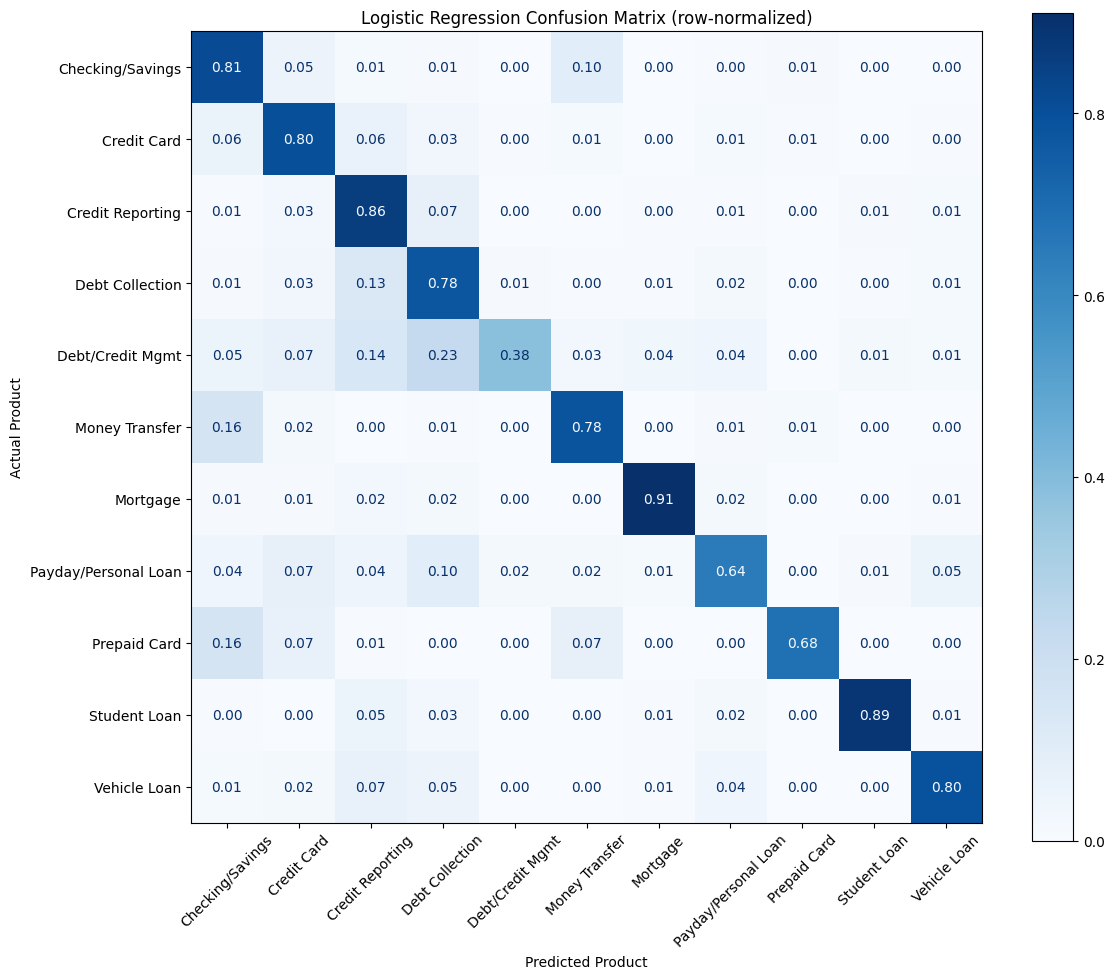

In [12]:
labels = best_lr.classes_
display_labels = [SHORT_LABELS[label] for label in labels]

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=display_labels,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
)

ax.set_title("Logistic Regression Confusion Matrix (row-normalized)")
ax.set_xlabel("Predicted Product")
ax.set_ylabel("Actual Product")

plt.tight_layout()
plt.savefig(figures_dir / f"{MODEL_KEY}_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Most Influential Terms per Product (Explainability Preview)

Each product has its own coefficient vector. The terms with the largest positive coefficients push a complaint
most strongly toward that product. (In a softmax model coefficients are relative to the other classes, so they are
best read as "evidence for this product versus the rest".) A fuller analysis, including negative terms and
per-complaint word contributions, is in `04_explainability_error_analysis.ipynb`.

In [13]:
feature_names = vectorizer.get_feature_names_out()
TOP_N = 10

top_terms = pd.DataFrame(
    {
        SHORT_LABELS[label]: feature_names[np.argsort(best_lr.coef_[i])[::-1][:TOP_N]]
        for i, label in enumerate(best_lr.classes_)
    },
    index=pd.RangeIndex(1, TOP_N + 1, name="rank"),
).T

top_terms

rank,1,2,3,4,5,6,7,8,9,10
Checking/Savings,bank,chase,cd,chime,funds,account,deposit,overdraft,sofi,usaa
Credit Card,card,capital,synchrony,citi,credit card,chase,discover,barclays,citibank,credit
Credit Reporting,equifax,experian,transunion,inquiries,report,credit,reporting,accounts,late,inquiry
Debt Collection,debt,collection,collections,collect,credit,credit card,owed,owe,recovery,apartment
Debt/Credit Mgmt,debt,credit,experian,debt relief,creditors,modification,mortgage,kikoff,services,debts
Money Transfer,zelle,paypal,coinbase,transfer,money,cashapp,venmo,transaction,wire,funds
Mortgage,mortgage,heloc,escrow,loan,home,foreclosure,closing,appraisal,pennymac,newrez
Payday/Personal Loan,loan,affirm,klarna,personal loan,line credit,acima,solar,onemain,upstart,advance
Prepaid Card,card,prepaid,netspend,funds,gift,unemployment,cards,cash app,money,way2go
Student Loan,mohela,nelnet,navient,student,loans,aidvantage,edfinancial,loan,school,forbearance


## 7. Save Metrics

Metrics are saved in the shared JSON format so `model_comparison.ipynb` can compare all models.

In [14]:
report = classification_report(y_test, y_pred, output_dict=True)

per_class = {
    label: {
        "precision": float(report[label]["precision"]),
        "recall": float(report[label]["recall"]),
        "f1": float(report[label]["f1-score"]),
        "support": int(report[label]["support"]),
    }
    for label in labels
}

metrics = {
    "model": MODEL_KEY,
    "display_name": "Logistic Regression",
    "task": "product",
    "features": "TF-IDF 1-2 grams (100k)",
    "best_params": {
        "C": float(grid.best_params_["C"]),
        "class_weight": grid.best_params_["class_weight"],
    },
    "cv_macro_f1": float(grid.best_score_),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "per_class": per_class,
    "train_seconds": float(train_seconds),
    "n_train": int(X_train.shape[0]),
    "n_test": int(X_test.shape[0]),
}

metrics_path = metrics_dir / f"{MODEL_KEY}.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("Saved metrics to", metrics_path)

Saved metrics to ..\..\results\metrics\logistic_regression.json


## 8. Save the Deployable Model

The fitted vectorizer and the tuned classifier (both trained on the training split only) are combined into one
scikit-learn `Pipeline`, so the saved model takes cleaned narrative strings directly. It is reloaded below to
confirm the saved file reproduces the in-notebook predictions. (`models/` is not committed to git.)

In [15]:
product_pipeline = Pipeline([
    ("tfidf", vectorizer),
    ("clf", best_lr),
])

model_path = models_dir / "product_logreg.joblib"
joblib.dump(product_pipeline, model_path, compress=3)

print("Saved model to", model_path)
print(f"File size: {model_path.stat().st_size / 1e6:.1f} MB")

Saved model to ..\..\models\product_logreg.joblib
File size: 9.7 MB


In [16]:
loaded_pipeline = joblib.load(model_path)

n_check = 25
sample_text = X_test_text.iloc[:n_check]

reloaded_pred = loaded_pipeline.predict(sample_text)
reloaded_proba = loaded_pipeline.predict_proba(sample_text)

assert (reloaded_pred == y_pred[:n_check]).all()
assert np.allclose(reloaded_proba, best_lr.predict_proba(X_test[:n_check]))
print(f"Reloaded pipeline reproduces predictions and probabilities on {n_check} test complaints.")

# Example: top-3 products for one test complaint
example_proba = reloaded_proba[0]
top3 = np.argsort(example_proba)[::-1][:3]

print()
print("Narrative (first 300 chars):", sample_text.iloc[0][:300], "...")
print("Actual product:", y_test.iloc[0])
for idx in top3:
    print(f"  {loaded_pipeline.classes_[idx]:<55} {example_proba[idx]:.3f}")

Reloaded pipeline reproduces predictions and probabilities on 25 test complaints.

Narrative (first 300 chars): ssue : failure to provide proper debt validation inaccurate reporting under the fair debt collection practices act ( fdcpa ) and fair credit reporting act ( fcra ). details : on , i submitted a complaint regarding ncb management services reporting an alleged dollaramount debt without providing prope ...
Actual product: Debt collection
  Debt collection                                         0.853
  Credit reporting or other personal consumer reports     0.068
  Vehicle loan or lease                                   0.039


## 9. Comparison with Naive Bayes

The saved metrics files are loaded to compare this model with the Naive Bayes baseline(s) on the same test split.

In [17]:
compare_keys = ["naive_bayes", "complement_nb", MODEL_KEY]

rows = []
per_class_f1 = {}

for key in compare_keys:
    path = metrics_dir / f"{key}.json"
    if not path.exists():
        print(f"No metrics file yet for '{key}' - skipped.")
        continue

    m = json.loads(path.read_text(encoding="utf-8"))
    name = m.get("display_name", key)

    rows.append({
        "model": name,
        "cv_macro_f1": m.get("cv_macro_f1"),
        "test_accuracy": m["test_accuracy"],
        "test_macro_f1": m["test_macro_f1"],
        "test_weighted_f1": m["test_weighted_f1"],
        "train_seconds": m.get("train_seconds"),
    })
    per_class_f1[name] = {
        SHORT_LABELS.get(product, product): scores["f1"]
        for product, scores in m["per_class"].items()
    }

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,cv_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,train_seconds
model,,,,,
Multinomial Naive Bayes,0.7190,0.7494,0.7230,0.7463,0.4645
Complement Naive Bayes,0.7210,0.7586,0.7211,0.7514,0.4606
Logistic Regression,0.7708,0.7978,0.7760,0.7955,62.0939


In [18]:
# Per-product test F1 for each model
pd.DataFrame(per_class_f1).round(3)

,Multinomial Naive Bayes,Complement Naive Bayes,Logistic Regression
Checking/Savings,0.721,0.722,0.776
Credit Card,0.715,0.730,0.791
Credit Reporting,0.808,0.807,0.831
Debt Collection,0.729,0.740,0.766
Debt/Credit Mgmt,0.457,0.434,0.500
Money Transfer,0.690,0.752,0.790
Mortgage,0.878,0.877,0.914
Payday/Personal Loan,0.603,0.545,0.673
Prepaid Card,0.685,0.654,0.762
Student Loan,0.897,0.886,0.908


## Logistic Regression Results Summary

- **Tuning.** The best configuration was **C = 4, class_weight = None** with a 3-fold CV macro-F1 of **0.771**
  (± 0.001). `class_weight="balanced"` at C = 4 was essentially tied (0.770). Balancing mattered only for the most
  regularized model (C = 0.25: 0.756 balanced vs 0.742 unbalanced), and C = 16 was slightly worse (0.764), so the
  grid brackets the optimum.
- **Test set.** Accuracy **79.8%**, macro-F1 **0.776**, weighted-F1 **0.796**. The test macro-F1 is in line with
  the CV estimate (0.771), so the tuning did not overfit. The final fit on all 130,000 training complaints took
  **62 s** (226 lbfgs iterations); the whole grid search took 8.2 minutes.
- **vs. Naive Bayes.** On the same split and features, Multinomial NB reached macro-F1 0.723 (accuracy 74.9%) and
  Complement NB 0.721 (75.9%) when this notebook was run. Logistic Regression improves macro-F1 by about
  **+5 points** and accuracy by about **+4 to 5 points**, and it beats Multinomial NB on **every one of the 11
  products**. The largest gains are Money Transfer (0.690 → 0.790), Prepaid Card (0.685 → 0.762), Credit Card
  (0.715 → 0.791) and Payday/Personal Loan (0.603 → 0.673).
- **Strongest / weakest products.** Mortgage (F1 0.914) and Student Loan (0.908) are easiest. **Debt or credit
  management** is by far the hardest (F1 0.500, recall only 0.38), followed by Payday/Personal Loan (0.673).
- **Most common confusions.** Debt/Credit Mgmt complaints are routed to Debt Collection (23%) or Credit Reporting
  (14%). Money Transfer and Prepaid Card complaints are each misrouted to Checking/Savings 16% of the time. Debt
  Collection goes to Credit Reporting 13% of the time, and Payday/Personal Loan goes to Debt Collection 10% of the time.
  These are products whose complaints genuinely overlap (e.g. a collection account that also appears on a credit report).
- **Top terms.** The strongest evidence for each product is largely **company and brand names** (Equifax /
  Experian / TransUnion, MOHELA / Nelnet / Navient, Zelle / PayPal / Coinbase, Netspend, Affirm / Klarna,
  Bridgecrest / Santander) plus product vocabulary (escrow, foreclosure, repossession, overdraft, forbearance).
  Company names are legitimately useful for routing, but they mean the model learns *who* the complaint is about as
  much as *what* it is about. Debt/Credit Mgmt's top terms (debt, credit, experian, mortgage, modification) overlap
  heavily with other products, which explains its low recall.